# Bonus Track 3.- Evaluacion de Modelos de Clasificacion


* Para los problemas de Clasificación se utilizan (entre otros) las siguientes métricas de evaluación:

    - ***Accuracy***
    - ***Precision***
    - ***Recall***
    - ***Specificity***
    - ***F-score***
    - ***Curva ROC***
    -  ***ROC_AUC: Área bajo la curva ROC***


* Para ver como clasifica el modelo generado usamos la denominada ***“Matriz de Confusión”*** en la cual se muestra el número de elementos que clasifica como verdaderos y falsos positivos y verdaderos y falsos negativos.


* Veamos a continuación los detalles de las métricas de evaluación y la matriz de confusión:


<hr>


## - Matriz de confusión

* Cuando hablamos de clasificación tenemos que medir cuanto hemos acertado y como lo hemos acertado, por ello las ***matrices de confusión nos ayudan a ver el acierto o fallo que tiene nuestro modelo a la hora de clasificar***. La matriz de confusión tiene la siguiente forma:

    - **True Positive (TP)**: Valores positivos clasificados como positivos
    - **True Negative (TN)**: Valores negativos clasificados como negativos
    - **False Positive (FP)**: Valores negativos clasificados como positivos
    - **False Negative (FN)**: Valore positivos clasificados como negativos
    
<img src="./imgs/2_02_01_eval.png" style="width: 400px;"/>


## - Accuracy

* Indica el porcentaje de acierto:

$$Acuracy = \frac{TP + TN}{TP + FN + FP + TN}$$

## - Precision

* Los positivos correctamente pronosticados entre todos los ejemplos pronosticados como positivos. 


* "***De lo que hemos pronosticado, cuanto hemos acertado***"


$$Precision = \frac{TP}{TP + FP}$$


<img src="./imgs/2_02_02_eval.png" style="width: 400px;"/>
                                                               
                                                               

## - Recall


* Los positivos correctamente pronosticados, entre todos los ejemplos que son positivos. 


* "***De lo que hay en realidad, cuanto hemos acertado***"


* Esta medida también se conoce con el nombre de ***Exhaustividad*** o ***Sensibilidad***.


$$Recall = \frac{TP}{TP + FN} = \frac{TP}{Positive}$$


<img src="./imgs/2_02_03_eval.png" style="width: 400px;"/>


## - Specificity


* Los negativos correctamente pronosticados, entre todos los ejemplos que son negativos. 


$$Specificity = \frac{TN}{TN + FP} = \frac{TN}{Negative}$$


<img src="./imgs/2_02_05_eval.png" style="width: 400px;"/>


## - F-Score (Precision-Recall)


* Es una media que ***combina la precisión y el recall con la media armonica de ambas medidas***. 


* Si es cercano a ***1***, la precisión y la sensibilidad de la clase positiva son altas para el umbral seleccionado. 


* Si es cercano a ***0***, al menos una de estas dos métricas es baja; no describe por sí sola todos los aspectos del clasificador.


* Se utiliza la media armonica, porque esta penaliza el hecho de que uno de los dos valores(el Precision o el Recall) tenga un valor bajo.


* El ***F1*** o ***F-score*** (siendo $score=1$) se calcula de la siguiente manera:


$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$


<img src="./imgs/2_02_03_eval.png" style="width: 400px;"/>


* Esta medida en realidad debería de llamarse $F_\beta$ calculandose de la siguiente manera:

$$F_\beta =  \frac{(1+\beta^2) \cdot Precision \cdot Recall}{\beta^2 \cdot Precision + Recall}$$


* En función del valor que le demos a $F_\beta$ la media armónica dará más importancia a la Precision o al Recall; por ejemplo:

    + $F_{0}$: Es la Precision (cuando está definida).
    + $F_{0.5}$: Da más peso a la Precision que al Recall.
    + $F_{1}$: Asigna el mismo peso a la Precision que al Recall.
    + $F_{2}$: Da más peso a la Recall que a la Precision.
    + $F_{\infty}$: Es el límite cuando $\beta$ tiende a infinito, igual al Recall (cuando está definido).
    
    
* ***F1 es el caso particular de F-beta con beta igual a 1, que pondera Precision y Recall por igual.***


## Curva ROC


* La ***curva ROC*** (***R***eceiver ***O***perating ***C***haracteristic) es una gráfica que ***representa la Tasa de Verdaderos Positivos (TPR) en el eje vertical frente a la Tasa de Falsos Positivos (FPR) en el eje horizontal***.

    <img src="./imgs/2_03_06_eval.png" style="width: 400px;"/>

* Siendo:
<br>

    + ***TPR***: Recall
        $$TPR = Recall = \frac{TP}{TP + FN} = \frac{TP}{Positive}$$
    + ***FPR***: Fall-out
        $$FPR = Fall-Out = \frac{FP}{FP + TN} = \frac{FP}{Negative}$$

* Para ***construir esta curva***:

    1. Nuestro ***modelo de clasificación nos tiene que devolver una probabilidad o score de pertenencia a la clase positiva y debemos de ordenar esa probabilidad o score de mayor a menor valor*** (de manera decreciente).
<br>

    2. ***Al recorrer los elementos ordenados*** vemos:
        + Al bajar el umbral e incluir un elemento de la clase positiva, aumenta la TPR.
        + Al incluir un elemento de la clase negativa, aumenta la FPR. Los elementos con la misma puntuación se procesan conjuntamente.
        
* La diagonal entre (0,0) y (1,1), normalmente discontinua, es una referencia de clasificación sin capacidad de discriminación. No es parte de la curva del modelo.


## - ROC_AUC: Área bajo la curva ROC


* El ***Área Bajo la Curva ROC (Area Under Curve), es el área que queda bajo la curva ROC*** y mide la capacidad del modelo para ordenar los ejemplos positivos por encima de los negativos, considerando distintos umbrales; no es la métrica precision.


* Un modelo que clasifique todos los elementos perfectamente, tendrá un ROC_AUC de 1.


* Cuando se representa la curva ROC se suele dibujar una curva diagonal (discontinua) que representa un clasificador cuyos elementos tienen todos la misma probabilidad o score y esta diagonal tiene un ROC_AUC de 0,5.


* Un AUC cercano a 0,5 indica poca capacidad de discriminación; cercano a 1 indica buena discriminación. Un AUC inferior a 0,5 indica que el orden de las puntuaciones tiende a ser inverso.


        
## - Métricas en Sckit-Learn:

* Scikit-Learn tiene implementados todos estos métodos de evaluación.


* Las métricas de clases reciben etiquetas reales y predichas. La curva ROC y el ROC AUC necesitan puntuaciones o probabilidades de la clase positiva:

    - **metrics.confusion_matrix(y_true, y_pred[, …])**: Compute confusion matrix to evaluate the accuracy of a classification
    - **metrics.accuracy_score(y_true, y_pred[, …])**: Accuracy classification score
    - **metrics.precision_score(y_true, y_pred[, …])**: Compute the precision
    - **metrics.recall_score(y_true, y_pred[, …])**: Compute the recall
    - **metrics.f1_score(y_true, y_pred[, labels, …])**: Compute the F1 score, also known as balanced F-score or F-measure
    - **metrics.classification_report(y_true, y_pred)**: Build a text report showing the main classification metrics
    - **metrics.roc_auc_score(y_true, y_score[, …])**: Compute Area Under the Receiver Operating Characteristic Curve (ROC AUC) from prediction scores.
    - **metrics.roc_curve(y_true, y_score[, …])**: Compute Receiver operating characteristic (ROC)


<hr>


# Ejemplo: Clasificación Binaria


* Supongamos que tenemos que clasificar 10 elementos de dos clases y la realizadad y la predicción vienen dados por:

    - y_real =    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
    - y_predict = [1, 1, 0, 1, 1, 0, 0, 1, 1, 0]


In [1]:
y_real =    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
y_predict = [1, 1, 0, 1, 1, 0, 0, 1, 1, 0]

### - Matriz de confusión

* En el ejemplo tenemos:

    - 5 elementos que son de la clase 0
    - 5 elementos que son de la clase 1
    - True Positive (TP): De los que son de la clase 1, predigo 4 correctamente.
    - False Negative (FN): De los que son de la clase 1, predigo 1 incorrectamente.
    - True Negative (TN): De los que son de la clase 0, predigo 3 correctamente.
    - False Positive (FP): De los que son de la clase 0, predigo 2 incorrectamente.
    
    

* Podemos ver este resultado en la matriz de confusión:

In [2]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_true=y_real, y_pred=y_predict, labels=[1, 0])

array([[4, 1],
       [2, 3]])

### - Accuracy

* Basandonos en el ejemplo, calculamos el accuracy como:

$$Acuracy = \frac{TP + TN}{TP + FN + FP + TN} = \frac{4 + 3}{4 + 1 + 2 + 3} = \frac{7}{10} = 0.7$$

In [3]:
from sklearn.metrics import accuracy_score

accuracy_score(y_true=y_real, y_pred=y_predict)

0.7

### - Precision

* Basandonos en el ejemplo, calculamos la precision como:

$$Precision = \frac{TP}{TP + FP} = \frac{4}{4 + 2} = \frac{4}{6} = 0.67$$

In [4]:
from sklearn.metrics import precision_score

precision_score(y_true=y_real, y_pred=y_predict)

0.6666666666666666

### - Recall

* Basandonos en el ejemplo, calculamos el recall como:

$$Recall = \frac{TP}{TP + FN} = \frac{4}{4 + 1} = \frac{4}{5} = 0.8$$

In [5]:
from sklearn.metrics import recall_score

recall_score(y_true=y_real, y_pred=y_predict)

0.8

### - F1

* Basandonos en el ejemplo, calculamos el F1 como:

$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall} = 2 \cdot \frac{0.67 \cdot 0.8}{0.67 + 0.8} = 2 \cdot \frac{0.54}{1.47} = 0.73$$

In [6]:
from sklearn.metrics import f1_score

f1_score(y_true=y_real, y_pred=y_predict)

0.7272727272727273

### - Curva ROC - Área bajo la curva

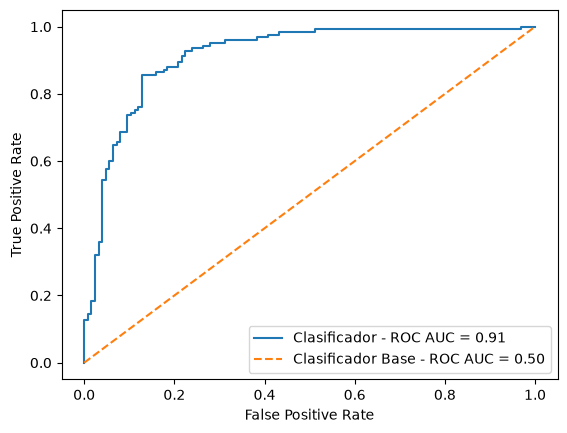

In [7]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
%matplotlib inline

# Generamos un conjunto de datos de prueba con 2 clases
X, y = make_classification(n_samples=1000, n_classes=2, random_state=1)

# Separamos entrenamiento y test para evaluar con datos no usados al entrenar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
clf = LogisticRegression(solver='lbfgs')
clf.fit(X_train, y_train)
X_probs = clf.predict_proba(X_test)

# Clasificador base: Clasificador con probabilidad de todos los elementos a cero
X_base_prob = [0 for i in range(len(y_test))]


# Obtenemos Tasa de Verdaderos Positivos (TPR), Tasa de Falsos Positivos (FPR) y el umbral
base_fpr, base_tpr, base_thresholds = roc_curve(y_test, X_base_prob)
clf_fpr, clf_tpr, clf_thresholds = roc_curve(y_test, X_probs[:, 1])

# Calculamos el Área bajo la curva
base_auc = roc_auc_score(y_test, X_base_prob)
clf_auc = roc_auc_score(y_test, X_probs[:, 1])

# Pintamos la curva ROC
plt.plot(clf_fpr, clf_tpr, label='Clasificador - ROC AUC = {:0.2f}'.format(clf_auc))
plt.plot(base_fpr, base_tpr, linestyle='--', label='Clasificador Base - ROC AUC = {:0.2f}'.format(base_auc))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

<hr>

## - Heatmap - Matriz de Confusión

* Para representar de una forma visual más agradable y legible la matriz de confusión, podemos usar el siguiente código que tiene la función "plot_confusion_matrix()"

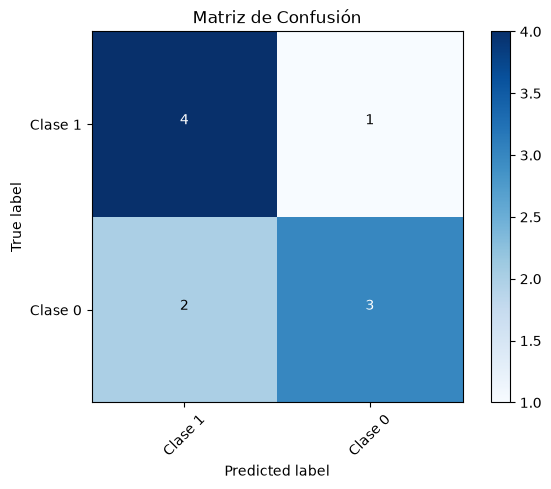

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
%matplotlib inline

def plot_confusion_matrix(cm, classes, title, cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'), horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

plt.figure()
matriz_confusion = confusion_matrix(y_true=y_real, y_pred=y_predict, labels=[1, 0])
plot_confusion_matrix(matriz_confusion, classes=['Clase 1', 'Clase 0'], title='Matriz de Confusión')
plt.show()

<hr>


# Ejemplo: Clasificación Múltiple


* Para el caso de la clasificación múltiple las métricas son las mismas, pero el procedimiento para calcularlo es diferente.


* Precision, recall y F1 pueden calcularse para cada clase mediante el enfoque uno contra el resto, y resumirse con promedios macro o ponderados. La accuracy global es la proporción de aciertos sobre todos los ejemplos. La extensión de ROC AUC a varias clases requiere opciones adicionales.


* Veamos el siguiente ejemplo en el que tenemos:

    - y_real =    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2]
    - y_predict = [1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 2, 1, 1, 0, 2]
    
    
* Tendríamos que calcular las metricas para las clases 0, 1 y 2 considerando:
<span></span><br><br>
    - ***Clase 0***: Consideramos la Clase 0 como la que es y el resto de clases como una misma Clase X
        + y_real =    [X, X, X, X, X, 0, 0, 0, 0, 0, X, X, X, X, X]
        + y_predict = [X, X, 0, X, X, 0, 0, X, X, 0, X, X, X, 0, X]
<span></span><br><br>        
    - ***Clase 1***: Consideramos la Clase 1 como la que es y el resto de clases como una misma Clase X
        + y_real =    [1, 1, 1, 1, 1, X, X, X, X, X, X, X, X, X, X]
        + y_predict = [1, 1, X, 1, 1, X, X, 1, 1, X, X, 1, 1, X, X]
<span></span><br><br>        
    - ***Clase 2***: Consideramos la Clase 2 como la que es y el resto de clases como una misma Clase X
        + y_real =    [X, X, X, X, X, X, X, X, X, X, 2, 2, 2, 2, 2]
        + y_predict = [X, X, X, X, X, X, X, X, X, X, 2, X, X, X, 2]


* Veamos a continuación un ejemplo, en el que usaremos la función "classification_report()" que nos devolverá las métricas vistas anteriormente por clase:

In [9]:
y_real =    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2]
y_predict = [1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 2, 1, 1, 0, 2]

from sklearn.metrics import classification_report

print(classification_report(y_true=y_real, y_pred=y_predict))

              precision    recall  f1-score   support

           0       0.60      0.60      0.60         5
           1       0.50      0.80      0.62         5
           2       1.00      0.40      0.57         5

    accuracy                           0.60        15
   macro avg       0.70      0.60      0.60        15
weighted avg       0.70      0.60      0.60        15



* Veamos a continuación la matriz de confusión:

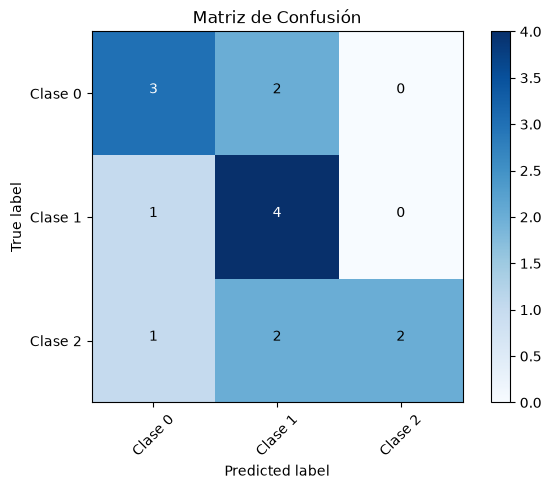

In [10]:
plt.figure()
matriz_confusion = confusion_matrix(y_true=y_real, y_pred=y_predict, labels=[0, 1, 2])
plot_confusion_matrix(matriz_confusion, classes=['Clase 0', 'Clase 1', 'Clase 2'], title='Matriz de Confusión')
plt.show()